In [1]:

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Load cleaned products and training interactions
data_dir = Path("../data/processed")

products_df = pd.read_csv(
    data_dir / "product_info_cleaned.csv"
)

train_df = pd.read_csv(
    data_dir / "train_interactions.csv"
)

test_df = pd.read_csv(
    data_dir / "test_interactions.csv"
)

print("Products:", products_df.shape)
print("Train interactions:", train_df.shape)
print("Test interactions:", test_df.shape)

print("\nUnique training users:",
      train_df["author_id"].nunique())

display(products_df[
    ["product_id", "product_name", "brand_name"]
].head())


Products: (8494, 28)
Train interactions: (213982, 4)
Test interactions: (66871, 4)

Unique training users: 30062


/var/folders/k9/vwyp856537l7qpcqffk02grm0000gn/T/ipykernel_4336/2626500338.py:15: DtypeWarning: Columns (0: author_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(


,product_id,product_name,brand_name
0,P473671,Fragrance Discovery Set,19-69
1,P473668,La Habana Eau de Parfum,19-69
2,P473662,Rainbow Bar Eau de Parfum,19-69
3,P473660,Kasbah Eau de Parfum,19-69
4,P473658,Purple Haze Eau de Parfum,19-69


In [2]:

# Convert product content into numerical vectors

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    min_df=2,
    ngram_range=(1, 2),
    dtype=np.float32
)

tfidf_matrix = tfidf.fit_transform(
    products_df["combined_features"].fillna("")
)

print("TF-IDF MATRIX CREATED")
print("-" * 40)

print("Matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Non-zero values:", tfidf_matrix.nnz)


TF-IDF MATRIX CREATED
----------------------------------------
Matrix shape: (8494, 10000)
Vocabulary size: 10000
Non-zero values: 1062856


In [3]:

# Map product IDs to their positions in TF-IDF matrix

product_indices = pd.Series(
    products_df.index,
    index=products_df["product_id"]
)

print("Total indexed products:", len(product_indices))

sample_id = products_df.iloc[0]["product_id"]

print("Example product ID:", sample_id)
print("Matrix position:", product_indices[sample_id])



Total indexed products: 8494
Example product ID: P473671
Matrix position: 0


In [4]:

# Calculate similarity between two sample products

product_a = 0
product_b = 1

similarity = cosine_similarity(
    tfidf_matrix[product_a],
    tfidf_matrix[product_b]
)[0][0]

print("Product A:", products_df.iloc[product_a]["product_name"])
print("Product B:", products_df.iloc[product_b]["product_name"])

print("\nCosine Similarity:", round(float(similarity), 4))


Product A: Fragrance Discovery Set
Product B: La Habana Eau de Parfum

Cosine Similarity: 0.6646


In [5]:

# Content-Based Personalized Recommendation

def recommend_products(user_id, top_n=5):

    # Find products positively rated by the user in training
    user_history = train_df[
        train_df["author_id"] == user_id
    ]

    if user_history.empty:
        print("User not found in training data.")
        return pd.DataFrame()

    # Keep products available in the catalog
    liked_ids = user_history[
        "product_id"
    ].tolist()

    valid_ids = [
        pid for pid in liked_ids
        if pid in product_indices.index
    ]

    if not valid_ids:
        print("No matching products found.")
        return pd.DataFrame()

    # Get TF-IDF vectors of liked products
    liked_indices = [
        int(product_indices[pid])
        for pid in valid_ids
    ]

    # Build the user's preference profile
    user_profile = np.asarray(
        tfidf_matrix[liked_indices].mean(axis=0),
        dtype=np.float32
    )

    # Calculate cosine similarity against all products
    scores = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).ravel()

    # Exclude products already used in training
    scores[liked_indices] = -np.inf

    # Rank candidate products
    ranked_indices = np.argsort(scores)[::-1]

    top_indices = ranked_indices[
        np.isfinite(scores[ranked_indices])
    ][:top_n]

    # Return top recommendations
    recommendations = products_df.iloc[
        top_indices
    ][[
        "product_id",
        "product_name",
        "brand_name",
        "primary_category",
        "secondary_category",
        "rating",
        "price_usd"
    ]].copy()

    recommendations["similarity_score"] = (
        scores[top_indices]
    )

    return recommendations.reset_index(drop=True)


In [6]:

# Test the recommendation system with a sample user

sample_user = train_df["author_id"].iloc[0]

print("SELECTED USER:", sample_user)

print("\nPreviously liked products:")

display(
    train_df[
        train_df["author_id"] == sample_user
    ][["product_id", "rating"]].head(10)
)

print("\nTOP 5 RECOMMENDATIONS")

recommendations = recommend_products(
    sample_user,
    top_n=5
)

display(recommendations)


SELECTED USER: 10000117144

Previously liked products:


,product_id,rating
0,P453253,5.0
1,P427415,5.0
2,P440651,5.0
3,P428250,5.0
4,P504794,5.0



TOP 5 RECOMMENDATIONS


,product_id,product_name,brand_name,primary_category,secondary_category,rating,price_usd,similarity_score
0,P4016,Acne Control Clarifying Cleanser,Murad,Skincare,Cleansers,4.2348,36.0,0.492924
1,P456126,Vegan Milk Cleanser,MILK MAKEUP,Skincare,Cleansers,4.4259,30.0,0.357081
2,P467129,Acne Control 30-Day Trial Kit for Clearer Skin,Murad,Skincare,Value & Gift Sets,3.5333,36.0,0.355896
3,P503721,Salicylic Acid Acne Day Dots,Peace Out,Skincare,Treatments,4.4974,19.0,0.336601
4,P447596,100% Organic Cold-Pressed Moroccan Argan Oil,The Ordinary,Skincare,Moisturizers,4.1709,7.5,0.331514


In [8]:

# Evaluate recommendations for one user

def evaluate_user(user_id, k=5):

    recommendations = recommend_products(user_id, top_n=k)

    recommended_ids = recommendations["product_id"].tolist()

    relevant_ids = set(
        test_df.loc[
            test_df["author_id"] == user_id,
            "product_id"
        ]
    )

    if not relevant_ids:
        return None

    hits = [
        1 if pid in relevant_ids else 0
        for pid in recommended_ids
    ]

    # Precision@K
    precision = sum(hits) / k

    # Recall@K
    recall = sum(hits) / len(relevant_ids)

    # Average Precision@K
    cumulative_hits = 0
    precision_sum = 0

    for rank, hit in enumerate(hits, start=1):
        if hit:
            cumulative_hits += 1
            precision_sum += cumulative_hits / rank

    ap = precision_sum / min(len(relevant_ids), k)

    return {
        "user_id": user_id,
        "precision_at_5": precision,
        "recall_at_5": recall,
        "ap_at_5": ap,
        "hits": sum(hits)
    }



# Check user ID compatibility
print("Sample user:", repr(sample_user))
print("Train user type:", train_df["author_id"].dtype)
print("Test user type:", test_df["author_id"].dtype)

# Select a user present in both datasets
common_users = pd.Index(
    train_df["author_id"].unique()
).intersection(
    test_df["author_id"].unique()
)

print("Common users:", len(common_users))

if len(common_users) == 0:
    print("No matching users found. Check user ID data types.")
else:
    evaluation_user = common_users[0]

    result = evaluate_user(evaluation_user)

    if result is not None:
        print("\nEVALUATION RESULTS")
        print("-" * 40)

        for key, value in result.items():
            print(f"{key}: {value}")
    else:
        print("Evaluation could not be completed.")



Sample user: 10000117144
Train user type: object
Test user type: str
Common users: 11822

EVALUATION RESULTS
----------------------------------------
user_id: 46164044663
precision_at_5: 0.2
recall_at_5: 0.5
ap_at_5: 0.5
hits: 1


In [9]:

# Evaluate 100 users

# Standardize user ID types
train_df["author_id"] = train_df["author_id"].astype(str)
test_df["author_id"] = test_df["author_id"].astype(str)

# Find users present in both datasets
common_users = pd.Index(
    train_df["author_id"].unique()
).intersection(
    test_df["author_id"].unique()
)

# Select 100 random users
evaluation_users = pd.Series(
    common_users
).sample(
    n=min(100, len(common_users)),
    random_state=42
)

evaluation_results = []

for user_id in evaluation_users:
    result = evaluate_user(user_id, k=5)

    if result is not None:
        evaluation_results.append(result)

evaluation_df = pd.DataFrame(evaluation_results)

print("MODEL PERFORMANCE EVALUATION")
print("-" * 40)

print("Evaluated users:", len(evaluation_df))

print(
    "Precision@5:",
    round(evaluation_df["precision_at_5"].mean(), 4)
)

print(
    "Recall@5:",
    round(evaluation_df["recall_at_5"].mean(), 4)
)

print(
    "MAP@5:",
    round(evaluation_df["ap_at_5"].mean(), 4)
)

display(evaluation_df.head())


MODEL PERFORMANCE EVALUATION
----------------------------------------
Evaluated users: 100
Precision@5: 0.056
Recall@5: 0.1812
MAP@5: 0.1321


,user_id,precision_at_5,recall_at_5,ap_at_5,hits
0,7252834899,0.2,0.5,0.5,1
1,8875292082,0.0,0.0,0.0,0
2,8723943205,0.2,1.0,1.0,1
3,2626929493,0.0,0.0,0.0,0
4,2590921382,0.0,0.0,0.0,0


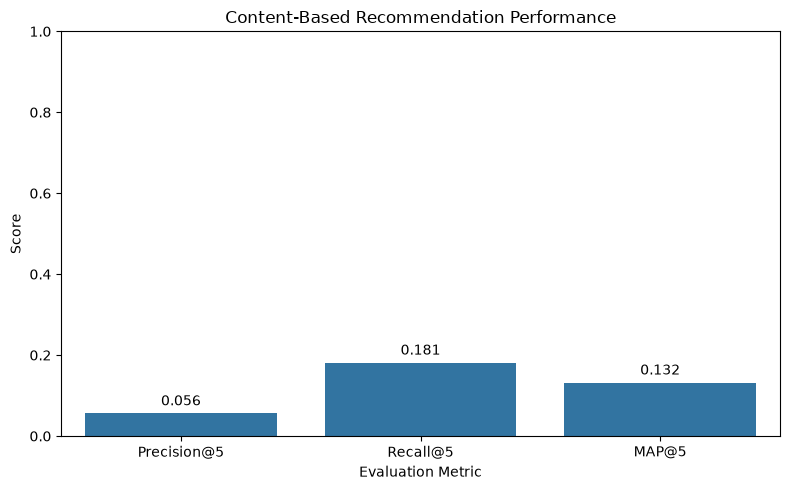

In [11]:

# Performance Metrics Visualization
import matplotlib.pyplot as plt
import seaborn as sns

metrics = {
    "Precision@5": evaluation_df["precision_at_5"].mean(),
    "Recall@5": evaluation_df["recall_at_5"].mean(),
    "MAP@5": evaluation_df["ap_at_5"].mean()
}

plt.figure(figsize=(8, 5))

sns.barplot(
    x=list(metrics.keys()),
    y=list(metrics.values())
)

plt.title("Content-Based Recommendation Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

plt.ylim(0, 1)

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()
